# Tiamat

**Autor**: Arthur Cunha Rangel de Sousa

**Disciplina**: Aprendizado de Máquina

**Instituição**: Ilum Escola de Ciência

## 1. Introdução

### 1.1. O Tiamat

O Tiamat, trabalho final da disciplina de Aprendizado de Máquina da Ilum Escola de Ciência, propõe que o estudante desenvolva todas as etapas de um fluxo completo de análise de dados, incluindo obtenção e tratamento dos dados, análise exploratória, construção de modelos preditivos, avaliação de desempenho e interpretação dos resultados.

Nesse contexto, o presente trabalho busca aplicar modelos de classificação para prever a ocorrência de violência unilateral contra civis a partir de características associadas a conflitos armados e ao contexto geopolítico dos países analisados.

### 1.2. O conjunto de dados

Para a realização deste estudo, foi utilizado o conjunto de dados UCDP Country-Year Dataset, desenvolvido pelo Uppsala Conflict Data Program (UCDP) [1]. O conjunto reúne informações anuais sobre diferentes formas de violência organizada ao redor do mundo, incluindo conflitos estatais, conflitos não estatais e violência unilateral contra civis. Cada observação representa um país em um determinado ano, contendo informações sobre a ocorrência desses eventos e métricas relacionadas à intensidade dos conflitos.

Neste trabalho, o objetivo consiste em prever a variável `os_exist`, que indica a ocorrência (ou não) de violência unilateral contra civis em um país durante um determinado ano. Para essa tarefa, foram utilizadas variáveis relacionadas à localização geográfica, ao período temporal e às características dos conflitos observados, como a existência de conflitos estatais e não estatais e o número de díades/organizações envolvidas em cada conflito.

## 2. Organização do conjunto de dados e análise exploratória

### 2.1 Organizando o conjunto de dados

Em primeiro lugar, será feita a análise exploratória do conjunto de dados. Será importado o dataset apresentado na introdução, a partir do qual se definirá o target e os atributos.

In [2]:
import pandas as pd

In [3]:
df = pd.read_csv("OrganizedViolenceCYDataSet26_1.csv")
df.head()

,country,country_id,year,region,govt_name,sb_exist,sb_dyad_count,sb_dyad_ids,sb_dyad_names,sb_deaths_parties,...,os_total_deaths_best,os_total_deaths_high,os_total_deaths_low,cumulative_total_deaths_parties_in_orgvio,cumulative_total_deaths_civilians_in_orgvio,cumulative_total_deaths_unknown_in_orgvio,cumulative_total_deaths_in_orgvio_best,cumulative_total_deaths_in_orgvio_high,cumulative_total_deaths_in_orgvio_low,Version
0,Afghanistan,700,1989,Asia,Government of Afghanistan,1,5,724; 726; 727; 729; 732,Government of Afghanistan - Hizb-i Islami-yi A...,1019,...,0,0,0,1065,303,4043,5411,17642,2141,26.1
1,Afghanistan,700,1990,Asia,Government of Afghanistan,1,5,724; 726; 727; 732; 733,Government of Afghanistan - Hizb-i Islami-yi A...,704,...,0,0,0,724,101,689,1514,2311,1359,26.1
2,Afghanistan,700,1991,Asia,Government of Afghanistan,1,4,724; 726; 727; 732,Government of Afghanistan - Hizb-i Islami-yi A...,2274,...,0,0,0,2274,49,1230,3553,4053,3407,26.1
3,Afghanistan,700,1992,Asia,Government of Afghanistan,1,4,724; 726; 727; 732,Government of Afghanistan - Hizb-i Islami-yi A...,187,...,8,304,8,187,1695,2503,4385,5865,4368,26.1
4,Afghanistan,700,1993,Asia,Government of Afghanistan,1,4,726; 732; 734; 842,Government of Afghanistan - Hizb-i Islami-yi A...,554,...,26,240,26,556,637,2912,4105,8433,4097,26.1


Serão mantidas apenas algumas colunas do conjunto de dados como atributos (e target), retirando identificadores únicos de cada país/região, colunas que seriam redundantes e dados que sejam identificavelmente correlacionados  a partir da leitura da referência [1] com outros atributos ou com o target, pois isso resultaria em um problema de vazamento de dados. Foram escolhidas as seguintes colunas:

**country**: o país ou território do conflito (categórico);

**year**: o ano em que o conflito ocorreu (numérico);

**region**: a região (continente ou região geopolítica que engloba países/territórios semelhantes de alguma forma) do conflito (categórico);

**sb_exist**: indica a existência de violência estatal dentro de um território em um dado ano (booleano);

**sb_dyad_count**: o número de grupos estatais envolvidos em violência organizadas dentro de um território em um dado ano (numérico);

**ns_exist**: indica a existência de violência não-estatal dentro de um território em um dado ano (booleano);

**os_exist** (o target): indica a existência de violência unilateral dentro de um território em um dado ano (booleano);

**ns_dyad_count**: o número de grupos não-estatais envolvidos em violência organizadas dentro de um território em um dado ano (numérico);

**sb_intrastate_exist**: indica a existência de violência **interna** estatal dentro de um território em um dado ano (booleano);

**sb_intrastate_dyad_count**: o número de organizações envolvidas em violência **interna** estatal dentro de um território em um dado ano (numérico);

**sb_interstate_exist**: indica a existência de violência **interestatal** estatal dentro de um território em um dado ano (booleano);

**sb_interstate_dyad_count**: o número de organizações envolvidas em violência **interestatal** estatal dentro de um território em um dado ano (numérico).

In [4]:
manter = ["country", "year", "region", "sb_exist", "sb_dyad_count", "ns_exist", "os_exist", "ns_dyad_count", "sb_intrastate_exist", "sb_intrastate_dyad_count", "sb_interstate_exist", "sb_interstate_dyad_count"]
df = df.drop(columns=[c for c in df.columns if c not in manter])

Para evitar possíveis inconsistências de tamanho das colunas, serão removidas todas as linhas com valores inexistentes em alguma coluna com `dropna()`.

In [5]:
df = df.dropna()
df.head()

,country,year,region,sb_exist,sb_dyad_count,sb_intrastate_exist,sb_intrastate_dyad_count,sb_interstate_exist,sb_interstate_dyad_count,ns_exist,ns_dyad_count,os_exist
0,Afghanistan,1989,Asia,1,5,1,5,0,0,1,2,0
1,Afghanistan,1990,Asia,1,5,1,5,0,0,1,1,0
2,Afghanistan,1991,Asia,1,4,1,4,0,0,1,2,0
3,Afghanistan,1992,Asia,1,4,1,4,0,0,1,1,1
4,Afghanistan,1993,Asia,1,4,1,4,0,0,1,1,1


### 2.2 Distribuições dos atributos

Vamos observar algumas estatíticas descritivas dos atributos e do target com `describe()`.

In [6]:
df.describe()

,year,sb_exist,sb_dyad_count,sb_intrastate_exist,sb_intrastate_dyad_count,sb_interstate_exist,sb_interstate_dyad_count,ns_exist,ns_dyad_count,os_exist
count,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000,7132.000000
mean,2007.210320,0.213825,0.522574,0.209619,0.498878,0.021873,0.023696,0.124369,0.446439,0.222518
std,10.615873,0.410033,1.431626,0.407065,1.363989,0.146280,0.163658,0.330025,2.006040,0.415966
min,1989.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1998.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2007.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2016.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,2025.000000,1.000000,16.000000,1.000000,16.000000,1.000000,2.000000,1.000000,35.000000,1.000000


Observando as estatísticas descritivas dos dados numéricos e booleanos (como estão entre 0 e 1, é possível tratá-los como numéricos), podemos chegar a algumas conclusões:

1. O tamanho do conjunto de dados está uniforme para todas as colunas escolhidas, o que era esperado após retirar as linhas com dados faltantes.
2. O atributo `year`, que representa o ano de um dado conflito, tem valor médio próximo de 2007, com mínimo em 1989, e máximo em 2025. Os dados parecem bem distribuídos ao longo dos quartis. O mesmo não se aplica para o restante dos atributos.
3. Os demais atributos e o target têm uma distribuição bastante não uniforme com todos os quartis sendo iguais a 0. Ou seja, pelo menos 75% das observações desses atributos são nulas.
4. Tratando individualmente as colunas a partir da observação 3, podemos identificar que o atributo `sb_exist`, que indica a existência de violência estatal em um determinado tem média igual a 0.2138 (aproximadamente). Isso quer dizer que 21,38% das observações território-ano sofreram com violência estatal.
5. Analisando `sb_instraste_exist` e `sb_interstate_exist`, podemos ver que os percentuais são também baixos: o primeiro ocorre em 20,96% das observações, e o segundo em apenas 2,19%. Ou seja, quase não há registros de violência interestatal no dataset.
6. Para os dados numéricos (com `_count` no final), podemos observar que os quartis também são todos nulos, e os valores máximos são bastante diferentes de 0. Ou seja, para a maioria das observações, não há organizações envolvidas em violência, seja interna ao território, interestatal ou não estatal.

Visando o entendimento das relações entre as colunas, e definindo `os_exist` como target, vamos a algumas análises por meio de gráficos, a começar pela distribuição do target, sobre a qual já é possível ter uma noção a partir do método `describe` utilizado antes.

Text(0.5, 1.0, 'Distribuição do target')

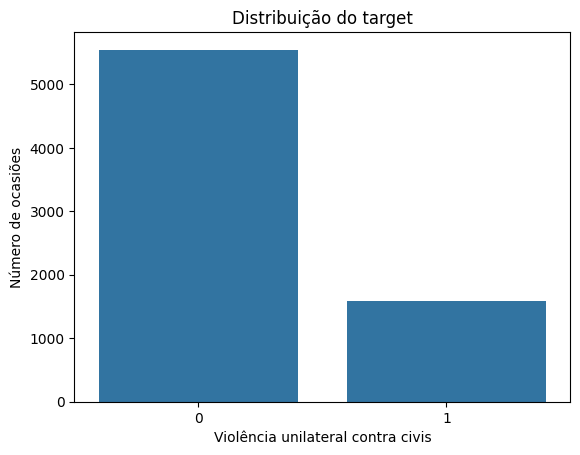

In [7]:
import seaborn as sns
import matplotlib.pyplot as mpl

sns.countplot(
    data=df,
    x="os_exist"
)

mpl.xlabel("Violência unilateral contra civis")
mpl.ylabel("Número de ocasiões")
mpl.title("Distribuição do target")

Observamos uma proporção grande de zeros em comparação a uns, ou seja, houve muito mais vezes em que não houve violência unilateral contra civis registrada em determinado ano comparado à quantidade de vezes em que houve. O desbalanço grande entre as categorias do target torna um modelo baseline que prevê a moda um bom modelo de previsão.

A seguir, serão plotados gráficos de barras dos atributos numéricos e booleanos a fim de investigar sua distribuição mais precisamente, algo que já começamos a observar usando o método `describe`.

Text(0.5, 1.0, 'Distribuição da quantidade de organizações não-estatais envolvidas em violência')

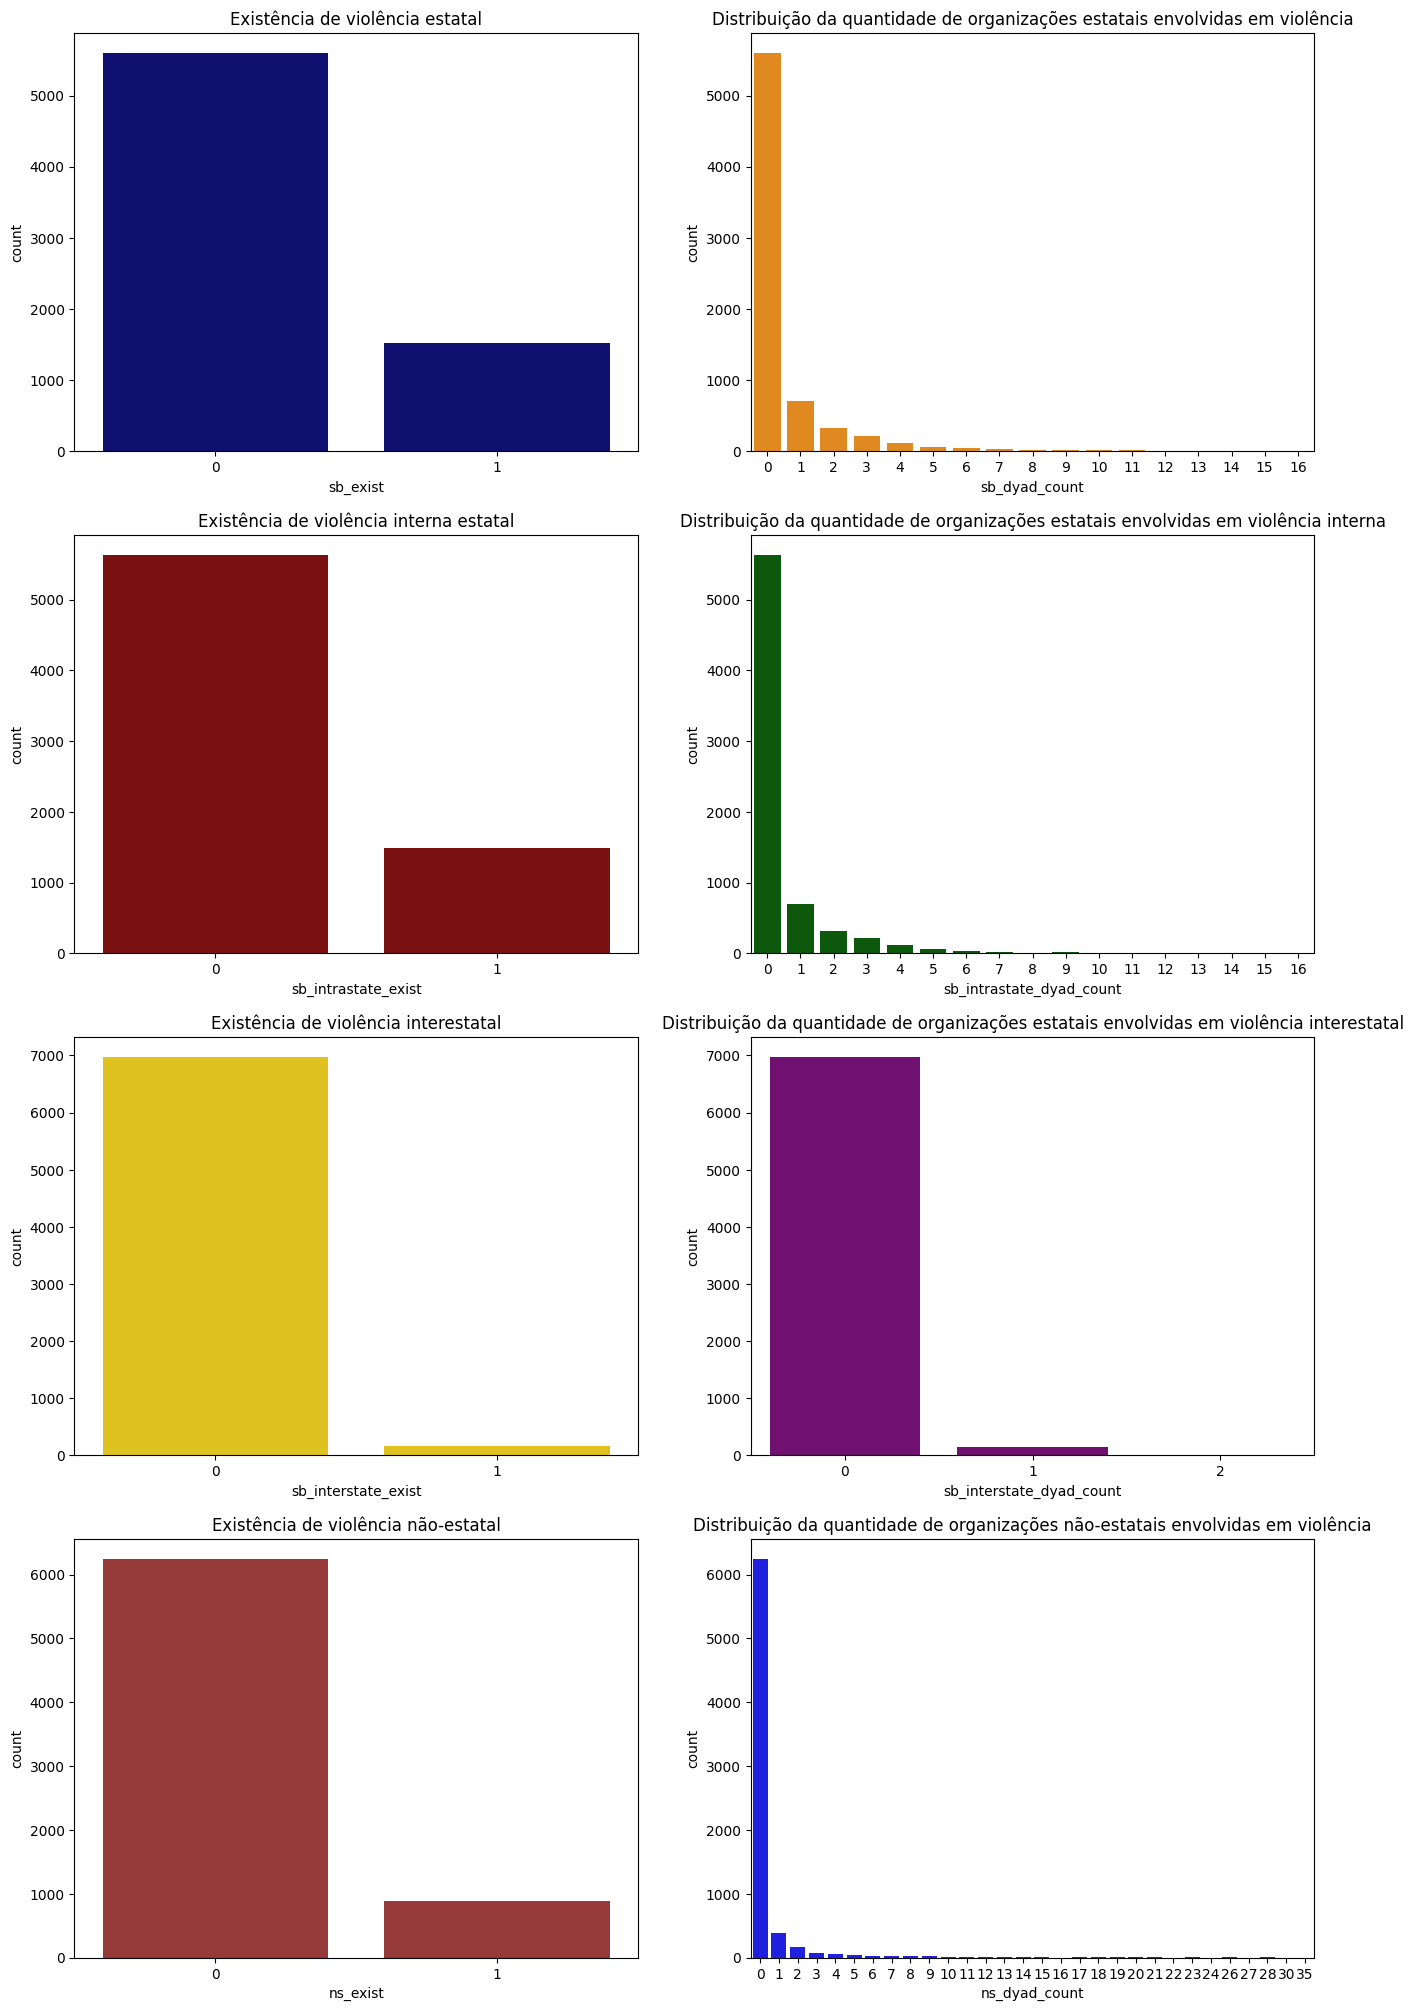

In [8]:
fig, axes = mpl.subplots(4, 2, figsize=(16, 25))

sns.countplot(
    data=df,
    x="sb_exist",
    color="navy",
    ax=axes[0,0]
)
axes[0,0].set_title("Existência de violência estatal")

sns.countplot(
    data=df,
    x="sb_dyad_count",
    color="darkorange",
    ax=axes[0,1]
)
axes[0,1].set_title("Distribuição da quantidade de organizações estatais envolvidas em violência")

sns.countplot(
    data=df,
    x="sb_intrastate_exist",
    color="darkred",
    ax=axes[1,0]
)
axes[1,0].set_title("Existência de violência interna estatal")

sns.countplot(
    data=df,
    x="sb_intrastate_dyad_count",
    color="darkgreen",
    ax=axes[1,1]
)
axes[1,1].set_title("Distribuição da quantidade de organizações estatais envolvidas em violência interna")

sns.countplot(
    data=df,
    x="sb_interstate_exist",
    color="gold",
    ax=axes[2,0]
)
axes[2,0].set_title("Existência de violência interestatal")

sns.countplot(
    data=df,
    x="sb_interstate_dyad_count",
    color="purple",
    ax=axes[2,1]
)
axes[2,1].set_title("Distribuição da quantidade de organizações estatais envolvidas em violência interestatal")

sns.countplot(
    data=df,
    x="ns_exist",
    color="brown",
    ax=axes[3,0]
)
axes[3,0].set_title("Existência de violência não-estatal")

sns.countplot(
    data=df,
    x="ns_dyad_count",
    color="blue",
    ax=axes[3,1]
)
axes[3,1].set_title("Distribuição da quantidade de organizações não-estatais envolvidas em violência")

Analisando os gráficos de barras plotados, há muito mais observações nulas que não nulas em todas as categorias, de forma geral, o que está em concordância com a distribuição dos quartis vista com `describe`. No entanto, há diferenças entre elas. Por exemplo, a fração de zeros em relação ao total das observações é decrescente na seguinte ordem: primeiro os atributos relacionados a violência interestatal (quase 7000 das 7132 observações), depois relacionados a violência não-estatal (mais de 6000 das 7132 observações), por fim as relacionadas a violência estatal (perto de 5500 das 7132 observações). Ou seja, a maioria das observações território-ano não possui registros de violência organizada documentados, e o mais incomum é que ela ocorra entre Estados.

### 2.3 Gráficos de correlação com o target e entre atributos

Seguindo com a análise exploratória, vamos plotar gráficos de barras dos atributos categóricos `region` e `year` em relação ao target, agrupando as observações em que o target é igual a 1 (ou seja, há violência unilateral contra civis) por região e por ano (separadamente).

Text(0.5, 1.0, 'Quantidade relativa de violência unilateral contra civis por região')

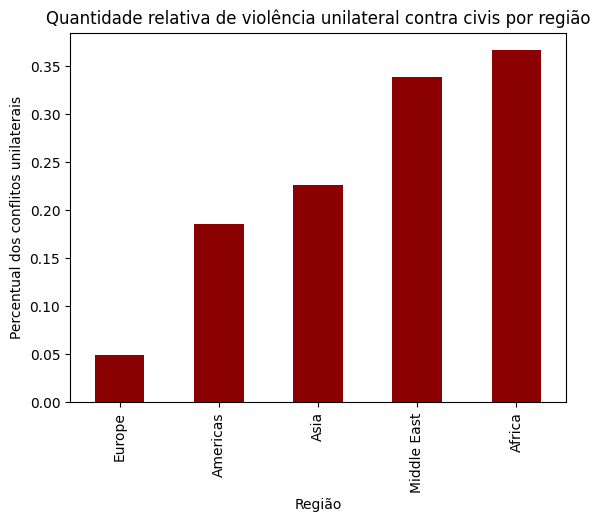

In [9]:
(df.groupby("region")["os_exist"]
      .mean()
      .sort_values(ascending=True)
      .plot(kind="bar",
           color="darkred")
)

mpl.xlabel("Região")
mpl.ylabel("Percentual dos conflitos unilaterais")
mpl.title("Quantidade relativa de violência unilateral contra civis por região")

O gráfico mostra que a existência do target igual a 1 é bastante mais comum nas regiões `África` e `Oriente Médio` (mais de 35% e por volta disso, respectivamente), e muito menos comum na `Europa` (menos de 5%), e moderada nas `Américas` e na `Ásia` (menos de 20% e um pouco mais que isso, respectivamente).

Fazendo o mesmo para cada ano:

Text(0.5, 1.0, 'Quantidade relativa de violência unilateral contra civis por ano')

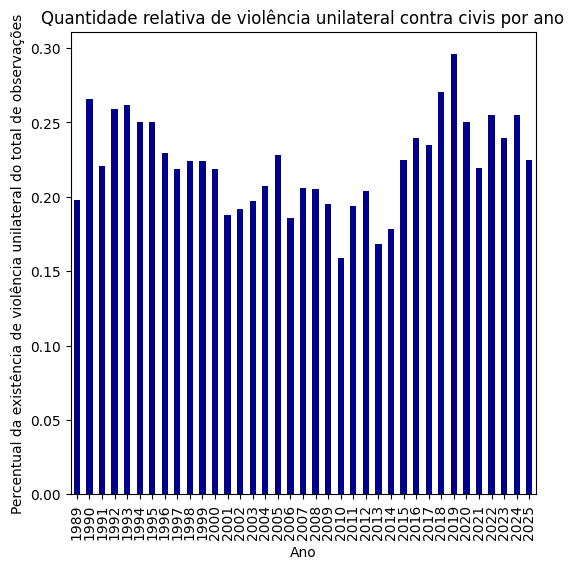

In [10]:
mpl.figure(figsize=(6, 6))

(df.groupby("year")["os_exist"]
    .mean()
    .plot(kind="bar", color="darkblue")
)

mpl.xlabel("Ano")
mpl.ylabel("Percentual da existência de violência unilateral do total de observações")
mpl.title("Quantidade relativa de violência unilateral contra civis por ano")

O gráfico não mostra nenhuma tendência linear clara de mudança com o passar dos anos. O período com menor número de registros do target igual a 1 é por volta do ano 2010, sendo este o ano específico com o menor índice. A partir da segunda metade da década de 2010, no entanto, observa-se um aumento significativo, voltando a um percentual similar ao dos anos 1990.

Na sequência, vamos montar mapas de calor mostrando a correlação entre o target e alguns atributos. O primeiro, correlacionando o target com `sb_exist` (a existência de violência estatal) [12].

Text(0.5, 1.0, 'Mapa de calor da correlação entre violência estatal e violência unilateral contra civis')

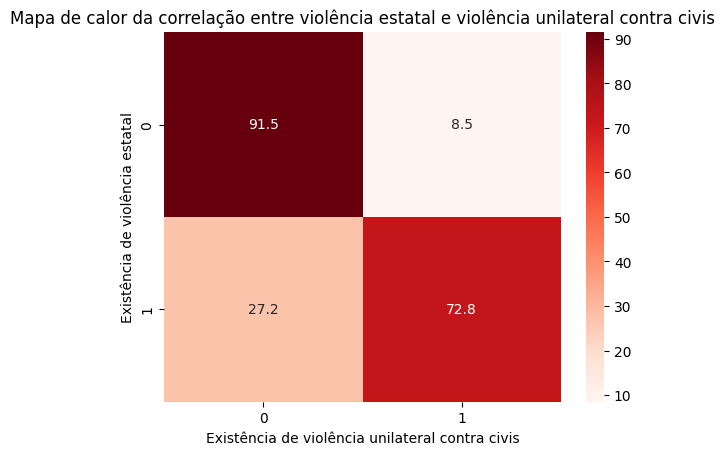

In [11]:
hm_sbos = pd.crosstab(
    df["sb_exist"],
    df["os_exist"],
    normalize="index"
) * 100

sns.heatmap(
    hm_sbos,
    annot=True,
    fmt=".1f",
    cmap="Reds"
)

mpl.xlabel("Existência de violência unilateral contra civis")
mpl.ylabel("Existência de violência estatal")
mpl.title("Mapa de calor da correlação entre violência estatal e violência unilateral contra civis")

O mapa de calor mostra que, quando há violência estatal (`sb_exist` é 1), em 72,8% dos casos há violência unilateral contra civis, e em 27,2% não há. Quando, do contrário não há registro de violência estatal, em 91,5% dos casos, também não há registro de violência unilateral contra civis; há apenas em 8,5%.

O mapa de calor a seguir relaciona o target com a violência não-estatal [12].

Text(0.5, 1.0, 'Mapa de calor da correlação entre violência não-estatal e violência unilateral contra civis')

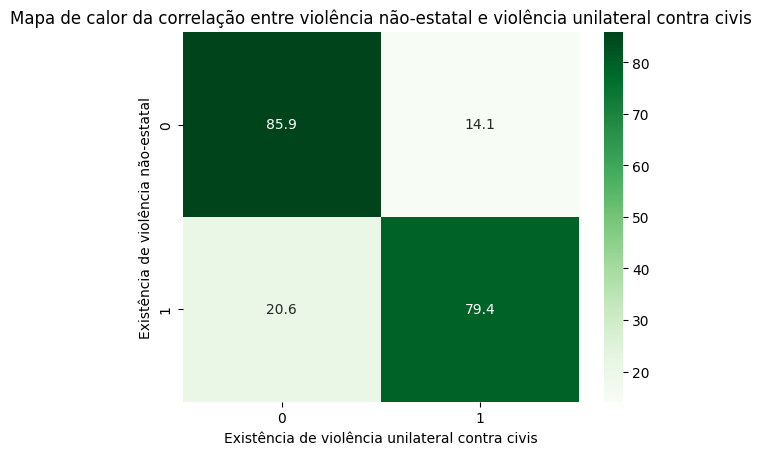

In [12]:
hm_nsos = pd.crosstab(
    df["ns_exist"],
    df["os_exist"],
    normalize="index"
) * 100

sns.heatmap(
    hm_nsos,
    annot=True,
    fmt=".1f",
    cmap="Greens"
)

mpl.xlabel("Existência de violência unilateral contra civis")
mpl.ylabel("Existência de violência não-estatal")
mpl.title("Mapa de calor da correlação entre violência não-estatal e violência unilateral contra civis")

Este mapa de calor mostra que, quando há violência não-estatal (`ns_exist` é 1), em 79,4% dos casos há violência unilateral contra civis, e em 20,6% não há. Quando, do contrário não há registro de violência não-estatal, em 85,9% dos casos, também não há registro de violência unilateral contra civis; há apenas em 14,1%.

O mapa de calor seguinte relaciona o target à violência estatal interna [12].

Text(847.0858585858584, 0.5, 'Violência estatal externa')

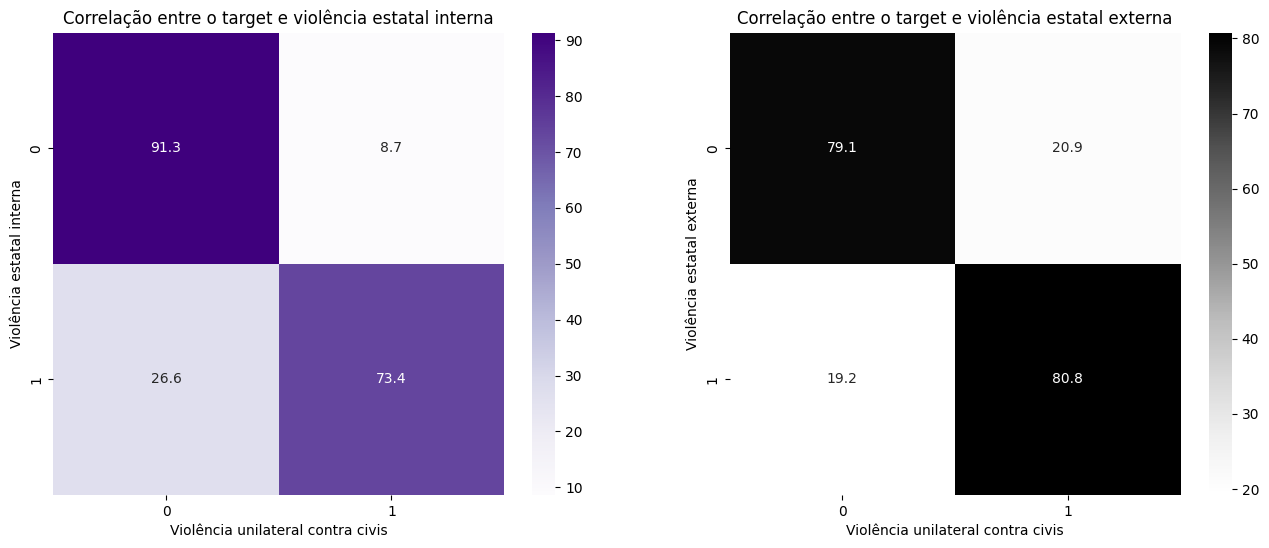

In [13]:
fig, axes = mpl.subplots(1, 2, figsize=(16, 6))

hm_sbios1 = pd.crosstab(
    df["sb_intrastate_exist"],
    df["os_exist"],
    normalize="index"
) * 100

hm_sbios2 = pd.crosstab(
    df["sb_interstate_exist"],
    df["os_exist"],
    normalize="index"
) * 100

sns.heatmap(
    hm_sbios1,
    annot=True,
    fmt=".1f",
    cmap="Purples",
    ax=axes[0]
)
axes[0].set_title("Correlação entre o target e violência estatal interna")
axes[0].set_xlabel("Violência unilateral contra civis")
axes[0].set_ylabel("Violência estatal interna")


sns.heatmap(
    hm_sbios2,
    annot=True,
    fmt=".1f",
    cmap="Greys",
    ax=axes[1]
)
axes[1].set_title("Correlação entre o target e violência estatal externa")
axes[1].set_xlabel("Violência unilateral contra civis")
axes[1].set_ylabel("Violência estatal externa")

O primeiro mapa de calor mostra que, quando há violência estatal interna (`sb_intrastate_exist` é 1), em 73,4% dos casos há violência unilateral contra civis, e em 26,6% não há. Quando, do contrário não há registro de violência estatal interna, em 91,5% dos casos, também não há registro de violência unilateral contra civis; há apenas em 8,5%.

Já o segundo mostra que, quando há violência estatal externa (`sb_interstate_exist` é 1), em 80,4% dos casos há violência unilateral contra civis, e em 19,2% não há. Quando, do contrário não há registro de violência estatal externa, em 79,1% dos casos, também não há registro de violência unilateral contra civis; há apenas em 20,9%.

Será montado um `boxplot` do target com `sb_dyad_count`, que pretende investigar a relação entre o número de organizações envolvidas em um conflito e o target.

<Axes: xlabel='os_exist', ylabel='sb_dyad_count'>

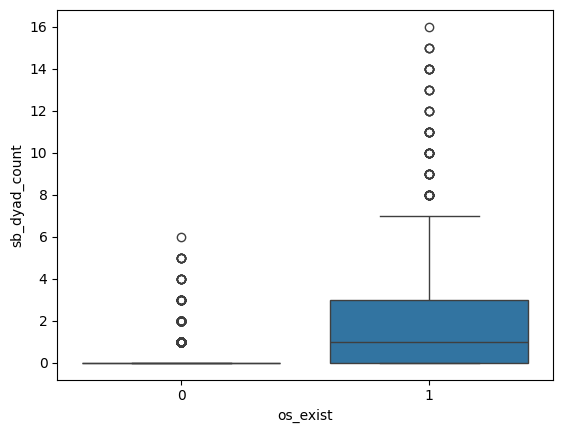

In [14]:
sns.boxplot(
    data=df,
    x="os_exist",
    y="sb_dyad_count"
)

O boxplot indica que observações com violência unilateral contra civis apresentam maior número de organizações em conflitos estatais. Além de uma mediana mais elevada, observa-se maior dispersão e a presença de casos considerados **outliers**, com alguns casos atingindo até 16 organizações. Esses resultados sugerem que conflitos mais complexos e fragmentados estão associados à ocorrência de violência unilateral contra civis.

Agora, será montada uma matriz de correlação entre os atributos numéricos e booleanos.

Text(0.5, 1.0, 'Matriz de correlação dos atributos numéricos e booleanos')

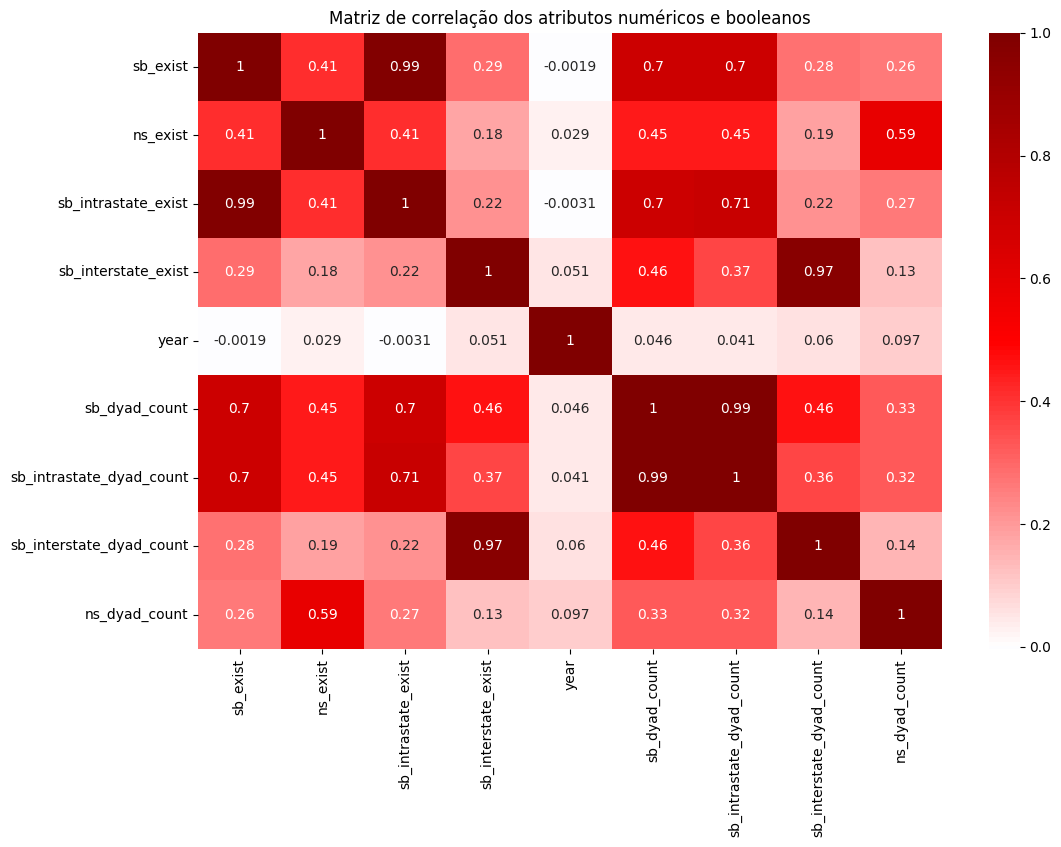

In [15]:
cols = [
    "sb_exist",
    "ns_exist",
    "sb_intrastate_exist",
    "sb_interstate_exist",
    "year",
    "sb_dyad_count",
    "sb_intrastate_dyad_count",
    "sb_interstate_dyad_count",
    "ns_dyad_count",
]
corr = df[cols].corr()

mpl.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="seismic",
    center=0
)

mpl.title("Matriz de correlação dos atributos numéricos e booleanos")

Analisando a matriz de correlação:
1. Os atributos `sb_exist` e `sb_instrastate_exist` têm correlação de 0,99, ou seja, são quase redundantes. Isso já era uma suspeita, quando identificamos os valores percentuais do total de observações muito semelhantes com `describe`, e quando identificamos uma semelhança nos gráficos de distribuição de ambos. Isso significa que quase todas as vezes que há violência estatal há violência estatal interna. É importante lembrar que a ocorrência de violência interna e externa não são exclusivas; é possível uma observação território-ano ter ambas as formas.
2. O mesmo ocorre para `sb_dyad_count` e `sb_intrastate_dyad_count`. Isso faz sentido, relacionando ao primeiro caso, pois já que a existência de violência estatal e violência estatal interna estão fortemente correlacionada, é de se esperar que as organizações envolvidas em ambas também estejam.
3. Os atributos `sb_interstate_exist` e `sb_interstate_dyad_count` têm uma correlação de 0,97. Isso porque, como observamos anteriormente com os gráficos de barras, os dois têm uma grande proporção de zeros em relação ao total de observações. Isso faz sentido, pois, se não há conflito interestatal, o número de organizações envolvidas também é nulo.
4. O atributo `year` não apresenta correlação significativa com nenhum outro atributo, sugerindo que não há relação temporal linear. É também o único que apresenta correlação inversa (sinal negativo), embora seja tão baixa, que não se pode considerá-la significativa.
5. Há outras correlações importantes a serem observadas, que não implicam em redundância, por exemplo, entre `sb_exist` e `ns_exist`, que é igual a 0,41. Ela indica que existe uma certa correlação entre violência estatal e não-estatal.

Feita a análise exploratória, seguiremos para a próxima etapa, que consiste em separar os dados em treino e teste.

## 3. Divisão dos dados em treino e teste

Para começar a treinar os modelos, precisamos separar os dados em treino e teste. No entanto, há um porém: como a proporção do target de zeros e uns está bastante desbalanceada, pode ser uma estratégia interessante fazer a estratificação do target, ou seja, manter a mesma proporção no conjunto de treino e de teste. Se isso não fosse feito, poderíamos obter uma proporção diferente no conjunto de teste, o que poderia acarretar em um problema se essa proporção fosse maior que a real do conjunto, pois um modelo ruim poderia obter uma acurácia muito boa sem estar aprendendo nada com os dados.

Código adaptado de [15].

In [16]:
from sklearn.model_selection import train_test_split

TAMANHO_TESTE = 0.2
SEMENTE_ALEATORIA = 66
TARGET = ["os_exist"]
ATRIBUTOS = ["country",
             "year",
             "region",
             "sb_exist",
             "sb_dyad_count",
             "ns_exist",
             "ns_dyad_count",
             "sb_intrastate_exist",
             "sb_intrastate_dyad_count",
             "sb_interstate_exist",
             "sb_interstate_dyad_count"
            ]


indices = df.index
indices_treino, indices_teste = train_test_split(
    indices,
    test_size=TAMANHO_TESTE,
    random_state=SEMENTE_ALEATORIA,
    stratify=df[TARGET]
)

df_treino = df.loc[indices_treino]
df_teste = df.loc[indices_teste]

X_treino = df_treino.reindex(ATRIBUTOS, axis=1)
y_treino = df_treino.reindex(TARGET, axis=1).values.ravel()

X_teste = df_teste.reindex(ATRIBUTOS, axis=1)
y_teste = df_teste.reindex(TARGET, axis=1).values.ravel()

Feita a divisão em treino e teste, seguiremos ao modelo `baseline`.

## 4. Modelo baseline

É interessante um modelo baseline para comparar posteriormente o desempenho dos modelos treinados com os dados. A estratégia de baseline adotada será a de prever o target mais frequente. Como os dados de treino e teste foram estratificados, é de se esperar que o baseline preveja na proporção de 0 e 1 do target que o conjunto de dados tem. Vamos calcular isso com a acurácia, cuja fórmula é: 
$$
\frac{(VP + VN)}{(VP + VN + FP + FN)}
$$
em que V indica verdadeiro, F falso, P positivo e N negativo. Ou seja, a acurácia mede o quanto o modelo previu corretamente entre todas as observações.

Código adaptado de [15].

Acurácia = 77.72%


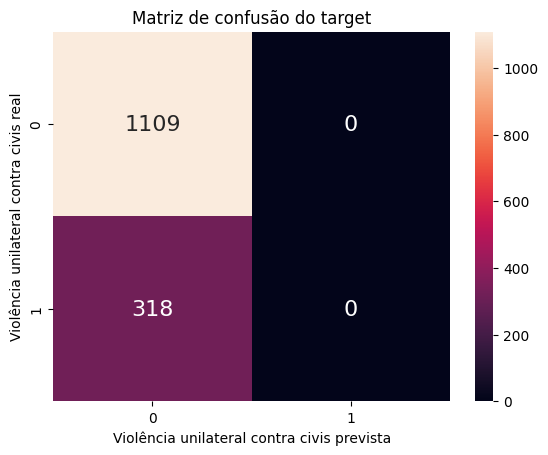

In [17]:
from sklearn.dummy import DummyClassifier

modelo_baseline = DummyClassifier()
modelo_baseline.fit(X_treino, y_treino)

from sklearn.metrics import confusion_matrix

y_verdadeiro = y_teste
y_previsao = modelo_baseline.predict(X_teste)

matriz_conf = confusion_matrix(y_verdadeiro, y_previsao)
df_conf = pd.DataFrame(matriz_conf)

sns.heatmap(df_conf,
            annot=True,
            annot_kws={"size": 16},
            fmt="d");

mpl.xlabel("Violência unilateral contra civis prevista")
mpl.ylabel("Violência unilateral contra civis real")
mpl.title("Matriz de confusão do target")

from sklearn.metrics import accuracy_score

acuracia = accuracy_score(y_verdadeiro, y_previsao)

print(f"Acurácia = {(acuracia*100):.2f}%")

Podemos observar exatamente o esperado: o `DummyClassifier` previu a classe mais frequente (0) para todos os casos. Também observamos uma acurácia de 77,72%, mas, embora seja um valor alto, há um grande problema associado a ele: o modelo não previu que existe violência unilateral contra civis em nenhum dos casos. A acurácia não demonstrou ser uma métrica boa. Vamos testar outras métricas de desempenho do `sklearn.metrics` [5]:

- `Recall`: retorna os positivos que o modelo conseguiu identificar, dentre todos os positivos reais:
$$
\frac{VP}{(VP+FN)}
$$.
- `Precision`: retorna a fração de positivos reais dentre todos os positivos previstos pelo modelo:
$$
\frac{VP}{VP+FP}
$$.
- `F1-score`: é a média harmônica entre `recall` e `precision`:
$$
2 \cdot \frac{recall \cdot precision}{recall+precision}
$$
- `ROC-AUC`: mede a probabilidade de o modelo atribuir uma pontuação maior a uma observação positiva do que a uma observação negativa escolhida aleatoriamente.

Vamos aos valores dessas métricas:

In [18]:
from sklearn.metrics import precision_score
precision = precision_score(y_verdadeiro, y_previsao)
print(f"Precision = {(precision*100):.2f}%")

from sklearn.metrics import recall_score
recall = recall_score(y_verdadeiro, y_previsao)
print(f"Recall = {(recall*100):.2f}%")

from sklearn.metrics import f1_score
f1 = f1_score(y_verdadeiro, y_previsao)
print(f"F1 = {(f1*100):.2f}%")

Precision = 0.00%
Recall = 0.00%
F1 = 0.00%


c:\venv\ilumpy\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


O resultado de todos foi de 0%! Mas isso era exatamente o esperado, se analisarmos bem as fórmulas. Todos eles dependem da previsão de um verdadeiro positivo para serem diferentes de 0, mas o baseline, como pudemos ver pela matriz de confusão, não prevê nenhuma observação como positiva.

In [19]:
from sklearn.metrics import roc_auc_score

y_prob = modelo_baseline.predict_proba(X_teste)[:, 1]

roc_auc = roc_auc_score(
    y_teste,
    y_prob
)

print(f"ROC-AUC = {(roc_auc*100):.2f}%")

ROC-AUC = 50.00%


Já a métrica ROC-AUC obteve 0,5, ou seja, o modelo não conseguiu ordenar positivos acima de negativos, o que é equivalente a uma previsão aleatória.

## 5. Pré-processamento dos dados

Alguns dos algoritmos que serão utilizados necessitam que haja um pré-processamento dos dados. Por exemplo, o `k-nn` calcula distâncias entre observações pelos atributos, então não é possível que ele lide com atributos categóricos. Vamos usar o `One Hot Encoder` para fazer o pré-processamento, transformando atributos categóricos em numéricos e normalizando os numéricos para garantir que todos os dados estejam na mesma escala. Vamos às importações e aos pré-processadores.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.impute import SimpleImputer

In [21]:
atributos_cat = ["country",
                 "region"
                ]
transf_cat = Pipeline(
    steps=[
        ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])

atributos_num = ["year",
                 "sb_dyad_count",
                 "ns_dyad_count",
                 "sb_intrastate_dyad_count",
                 "sb_interstate_dyad_count"
                ]
transf_num = Pipeline(
    steps=[
        ("scaler", StandardScaler())
    ])

preprocessador = ColumnTransformer(
    transformers=[
        ("cat", transf_cat, atributos_cat),
        ("num", transf_num, atributos_num), 
    ],
    remainder="passthrough"
)

Criado o pré-processador, podemos seguir.

## 6. Otimização de hiperparâmetros com optuna.

O `optuna` é um módulo que auxilia na resolução de problemas de otimização com parâmetros numéricos e categóricos, que fornece buscas mais "inteligentes" que a busca aleatória e mais eficientes que a busca em grade [notebook 7.1].

Para o Tiamat, o `optuna` foi utilizado na otimização dos hiperparâmetros dos algoritmos escolhidos, com o intuito de encontrar dentro dos espaços de busca definidos o melhor conjunto de hiperparâmetros para cada algoritmo.

Primeiro vamos importar o `optuna`, de tal forma que a sua saída fique mais limpa com a segunda linha da célula seguinte:

Códigos dessa seção adaptados de [15].

In [24]:
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

### 6.1 Regressão Logística

Vamos começar o processo com o primeiro algoritmo: de regressão logística. A escolha da regressõ logística como primeiro algoritmo se deve à sua maior rapidez, visto que o custo computacional do optuna é alto, então é importante verificar se o optuna está rodando adequadamente com um algoritmo mais rápido.

A Regressão Logística é um modelo linear de classificação que estima a probabilidade de ocorrência da classe positiva a partir de uma combinação linear dos atributos.

Para isso, devemos criar um instância que define o espaço de busca do optuna para os hiperparâmetros, usando o argumento `log=True` para navegar em escala logarítmica.

Os hiperparâmetros a serem variados da regressão logística serão:

- `C`: controla a força da regularização do modelo. Valores maiores punem mais os coeficientes do modelo, reduzindo o risco de overfitting, mas deixando-o mais simplificado;
- `fit_intercept`: especifica se uma constante deve ser adicionada à função de decisão;
- `class_weight`: ajusta os pesos das classes, na tentativa de compensar o desbalanceamento;
- `solver`: algoritmo numérico usado para encontrar os coeficientes da regressão logística. [6].

In [25]:
SEMENTE_ALEATORIA = 666

from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMENTE_ALEATORIA
)

def cria_instancia_rl(trial):

    parametros = {
        "C": trial.suggest_float(
            "C",
            1e-4,
            1e3,
            log=True
        ),

        "fit_intercept": trial.suggest_categorical(
            "fit_intercept",
            [True, False]
        ),

        "class_weight": trial.suggest_categorical(
            "class_weight",
            [None, "balanced"]
        ),

        "solver": trial.suggest_categorical(
            "solver",
            ["lbfgs", "liblinear", "newton-cg"]
        ),

        "random_state": SEMENTE_ALEATORIA,
        "max_iter": 5000,
    }

    modelo = LogisticRegression(**parametros)

    return modelo

Agora, vamos importar do `sci-kit learn` o `cross_val_score` para fazer a validação cruzada, e criar a **função objetivo**, que deve computar a métrica de interesse. Esta, será o **`f1_score`**, por ser uma combinação de `recall` e `precision`, é mais completa que as demais.

In [26]:
from sklearn.model_selection import cross_val_score


def funcao_objetivo_rl(trial):

    modelo = cria_instancia_rl(trial)

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessador),
               ("classifier", modelo)
              ]
    )

    metricas = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    return metricas.mean()

Feito isso, podemos passar ao próximo algoritmo.

### 6.2 K-NN

Seguimos ao próximo modelo: o k-nn. O algoritmo k-Nearest Neighbors classifica uma observação com base nas classes dos seus vizinhos mais próximos no espaço dos atributos.

Vamos criar a instância variando os hiperparâmetros:

- `n_neighbors`: varia o número de vizinhos que o modelo enxerga ao calcular a distância;
- `weights`: atribui pesos às distâncias
- `p`: altera na prática a métrica de distância. [7].

In [27]:
from sklearn.neighbors import KNeighborsClassifier

def cria_instancia_knn(trial):

    parametros = {
        "n_neighbors": trial.suggest_int(
            "n_neighbors",
            1,
            200,
        ),

        "weights": trial.suggest_categorical(
            "weights",
            ["uniform", "distance"]
        ),

        "p": trial.suggest_int(
            "p",
            1,
            3,
        ),
    }

    modelo = KNeighborsClassifier(**parametros)

    return modelo

Vamos à função objetivo, praticamente a mesma para todos os modelos.

In [28]:
def funcao_objetivo_knn(trial):

    modelo = cria_instancia_knn(trial)

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessador),
               ("classifier", modelo)
              ]
    )

    metricas = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    return metricas.mean()

### 6.3 Árvore de decisão

Seguindo com o próximo algoritmo: o de árvore aleatória. Árvores de decisão realizam classificações através de uma sequência de divisões dos dados, formando uma estrutura hierárquica de regras de decisão. A principal vantagem desse modelo é sua interpretabilidade, embora árvores individuais possam ser sensíveis a pequenas variações nos dados.

Vamos criar a instância, variando os seguintes hiperparâmetros:

- `criterion`: define a métrica utilizada para avaliar a qualidade das divisões realizadas pela árvore;
- `max_depth`: limita a profundidade máxima da árvore, controlando sua complexidade e reduzindo o risco de overfitting;
- `min_samples_split`: define o número mínimo de observações necessário para que um nó possa ser dividido;
- `min_samples_leaf`: define o número mínimo de observações que cada folha deve conter;
- `max_leaf_nodes`: limita a quantidade máxima de folhas que a árvore pode possuir;
- `class_weight`: ajusta o peso das classes para lidar com possíveis desbalanceamentos no conjunto de dados.[8].

In [29]:
from sklearn.tree import DecisionTreeClassifier

def cria_instancia_ad(trial):

    parametros = {

    "criterion": trial.suggest_categorical(
        "criterion",
        ["gini", "entropy", "log_loss"]
    ),

    "max_depth": trial.suggest_int(
        "max_depth",
        2,
        50
    ),

    "min_samples_split": trial.suggest_int(
        "min_samples_split",
        2,
        50
    ),

    "min_samples_leaf": trial.suggest_int(
        "min_samples_leaf",
        1,
        25
    ),

    "max_leaf_nodes": trial.suggest_int(
        "max_leaf_nodes",
        2,
        500
    ),

    "class_weight": trial.suggest_categorical(
        "class_weight",
        [None, "balanced"]
    ),

    "random_state": SEMENTE_ALEATORIA
}
    modelo = DecisionTreeClassifier(**parametros)

    return modelo

Agora a função objetivo:

In [30]:
def funcao_objetivo_ad(trial):

    modelo = cria_instancia_ad(trial)

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessador),
               ("classifier", modelo)
              ]
    )

    metricas = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    return metricas.mean()

### 6.4 Floresta aleatória

A Floresta Aleatória combina diversas árvores de decisão treinadas sobre subconjuntos aleatórios dos dados e dos atributos. Essa estratégia reduz a variância do modelo e geralmente produz previsões mais robustas do que uma única árvore.

Definindo o espaço de busca do `optuna` como:

- `n_estimators`: varia a quantidade de árvores que compõem a floresta;
- `criterion`: define a métrica utilizada pelas árvores para escolher as divisões dos dados;
- `max_depth`: limita a profundidade máxima de cada árvore da floresta;
- `min_samples_split`: define o número mínimo de observações necessário para realizar uma divisão em um nó;
- `min_samples_leaf`: determina o número mínimo de observações presentes em cada folha;
- `max_features`: controla a quantidade de atributos candidatos avaliados em cada divisão;
- `max_leaf_nodes`: limita a quantidade máxima de folhas em cada árvore;
- `bootstrap`: define se cada árvore será treinada utilizando amostras aleatórias com reposição;
- `class_weight`: ajusta o peso das classes para lidar com o desbalanceamento dos dados. [9].

In [31]:
from sklearn.ensemble import RandomForestClassifier

def cria_instancia_fa(trial):

    parametros = {

    "n_estimators": trial.suggest_int(
        "n_estimators",
        10,
        1000,
        log=True
    ),
        

    "criterion": trial.suggest_categorical(
        "criterion",
        ["gini", "entropy", "log_loss"]
    ),

    "max_depth": trial.suggest_int(
        "max_depth",
        2,
        50
    ),

    "min_samples_split": trial.suggest_int(
        "min_samples_split",
        2,
        50
    ),

    "min_samples_leaf": trial.suggest_int(
        "min_samples_leaf",
        1,
        25
    ),

    "max_features": trial.suggest_categorical(
        "max_features",
        ["sqrt", "log2", None]
    ),

    "max_leaf_nodes": trial.suggest_categorical(
        "max_leaf_nodes",
        [None, 10, 20, 50, 100, 200, 500]
    ),

    "bootstrap": trial.suggest_categorical(
        "bootstrap",
        [True, False]
    ),

    "class_weight": trial.suggest_categorical(
        "class_weight",
        [None, "balanced"]
    ),

    "n_jobs": -1,

    "random_state": SEMENTE_ALEATORIA
}
    modelo = RandomForestClassifier(**parametros)

    return modelo

Agora vamos à função objetivo:

In [32]:
def funcao_objetivo_fa(trial):

    modelo = cria_instancia_fa(trial)

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessador),
               ("classifier", modelo)
              ]
    )

    metricas = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    return metricas.mean()

### 6.5 Hist Gradient Boosting

Vamos ao último algoritmo: `HistGradientBoosting`. O HistGradientBoosting é um método de ensemble baseado em boosting, no qual várias árvores são construídas sequencialmente para corrigir os erros das árvores anteriores. A utilização de histogramas para discretizar os atributos numéricos reduz o custo computacional, tornando o algoritmo eficiente para conjuntos de dados tabulares de médio e grande porte.

Definindo o espaço de busca do `optuna` com os hiperparêmtros:

- ``learning_rate``: controla a intensidade da contribuição de cada árvore para o modelo final;
- ``max_iter``: varia a quantidade de árvores construídas durante o processo de boosting;
- ``max_depth``: limita a profundidade máxima das árvores utilizadas pelo algoritmo;
- ``max_leaf_nodes``: controla a quantidade máxima de folhas que cada árvore pode possuir;
- ``min_samples_leaf``: define o número mínimo de observações presentes em cada folha;
- ``l2_regularization``: aplica uma penalização aos valores das folhas para reduzir o risco de overfitting;
- ``early_stopping``: determina se o treinamento deve ser interrompido automaticamente quando não houver melhora no desempenho;
- ``max_bins``: define o número máximo de intervalos utilizados na discretização dos atributos numéricos. [10]

In [33]:
from sklearn.ensemble import HistGradientBoostingClassifier

def cria_instancia_hgb(trial):

    parametros = {

        "learning_rate": trial.suggest_float(
            "learning_rate",
            0.01,
            1.0,
            log=True
        ),

        "max_iter": trial.suggest_int(
            "max_iter",
            50,
            1000,
            log=True
        ),

        "max_depth": trial.suggest_int(
            "max_depth",
            2,
            30
        ),

        "max_leaf_nodes": trial.suggest_int(
            "max_leaf_nodes",
            10,
            500,
            log=True
        ),

        "min_samples_leaf": trial.suggest_int(
            "min_samples_leaf",
            1,
            50
        ),

        "l2_regularization": trial.suggest_float(
            "l2_regularization",
            1e-6,
            10,
            log=True
        ),

        "early_stopping": trial.suggest_categorical(
            "early_stopping",
            [True, False]
        ),

        "max_bins": trial.suggest_int(
            "max_bins",
            64,
            255
        ),

        "random_state": SEMENTE_ALEATORIA
    }
    
    modelo = HistGradientBoostingClassifier(**parametros)

    return modelo

Vamos à função objetivo:

In [34]:
def funcao_objetivo_hgb(trial):

    modelo = cria_instancia_hgb(trial)

    pipeline = Pipeline(
        steps=[("preprocessor", preprocessador),
               ("classifier", modelo)
              ]
    )

    metricas = cross_val_score(
        pipeline,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    )

    return metricas.mean()

Agora, vamos criar os estudos de fato, usando o argumento `direction=maximize` pois o nosso objetivo é maximizar a métrica de desempenho, no caso o F1-score. Além disso, os estudos serão persistidos em disco por meio do argumento storage, sendo utilizado conjuntamente com load_if_exists=True. Dessa forma, caso o kernel seja reiniciado ou a execução seja interrompida devido ao elevado custo computacional da otimização, o estudo poderá ser retomado do ponto em que foi interrompido, sem perda dos resultados já obtidos.

Para cada algoritmo, serão realizados 100 trials, sendo a avaliação de cada configuração de hiperparâmetros conduzida por meio de validação cruzada estratificada com cinco folds.

Ao final da otimização, serão armazenados o melhor conjunto de hiperparâmetros e o respectivo F1-score médio obtido na validação cruzada. Esses resultados serão posteriormente comparados entre os modelos avaliados e com o modelo baseline e entre si.

In [35]:
NOME_DO_ESTUDO_RL = "regressao_logistica"

objeto_de_estudo_rl = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO_RL,
    storage=f"sqlite:///{NOME_DO_ESTUDO_RL}.db",
    load_if_exists=True,
)

objeto_de_estudo_rl.optimize(
    funcao_objetivo_rl,
    n_trials=100,
)

melhor_trial_rl = objeto_de_estudo_rl.best_trial

print(f"Número do melhor trial de regressão logística: {melhor_trial_rl.number}")
print(f"F1 médio da regressão logística: {melhor_trial_rl.value:.4f}")
print(f"Parâmetros do melhor trial da regressão logística: {melhor_trial_rl.params}")

resultado_rl = {
    "modelo": "Logistic Regression",
    "f1_cv": melhor_trial_rl.value,
    "parametros": melhor_trial_rl.params
}



NOME_DO_ESTUDO_KNN = "knn"

objeto_de_estudo_knn = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO_KNN,
    storage=f"sqlite:///{NOME_DO_ESTUDO_KNN}.db",
    load_if_exists=True,
)

objeto_de_estudo_knn.optimize(
    funcao_objetivo_knn,
    n_trials=100
)

melhor_trial_knn = objeto_de_estudo_knn.best_trial

print(f"Número do melhor trial de knn: {melhor_trial_knn.number}")
print(f"F1 médio do knn: {melhor_trial_knn.value:.4f}")
print(f"Parâmetros do melhor trial do knn: {melhor_trial_knn.params}")

resultado_knn = {
    "modelo": "knn",
    "f1_cv": melhor_trial_knn.value,
    "parametros": melhor_trial_knn.params
}



NOME_DO_ESTUDO_AD = "arvore_de_decisao"

objeto_de_estudo_ad = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO_AD,
    storage=f"sqlite:///{NOME_DO_ESTUDO_AD}.db",
    load_if_exists=True,
)

objeto_de_estudo_ad.optimize(
    funcao_objetivo_ad,
    n_trials=100
)

melhor_trial_ad = objeto_de_estudo_ad.best_trial

print(f"Número do melhor trial da árvore de decisão: {melhor_trial_ad.number}")
print(f"F1 médio da árvore de decisão: {melhor_trial_ad.value:.4f}")
print(f"Parâmetros do melhor trial da árvore de decisão: {melhor_trial_ad.params}")

resultado_ad = {
    "modelo": "arvore_de_decisao",
    "f1_cv": melhor_trial_ad.value,
    "parametros": melhor_trial_ad.params
}



NOME_DO_ESTUDO_FA = "floresta_aleatoria"

objeto_de_estudo_fa = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO_FA,
    storage=f"sqlite:///{NOME_DO_ESTUDO_FA}.db",
    load_if_exists=True,
)

objeto_de_estudo_fa.optimize(
    funcao_objetivo_fa,
    n_trials=100
)

melhor_trial_fa = objeto_de_estudo_fa.best_trial

print(f"Número do melhor trial da floresta aleatória: {melhor_trial_fa.number}")
print(f"F1 médio da floresta aleatória: {melhor_trial_fa.value:.4f}")
print(f"Parâmetros do melhor trial da floresta aleatória: {melhor_trial_fa.params}")

resultado_fa = {
    "modelo": "floresta_aleatoria",
    "f1_cv": melhor_trial_fa.value,
    "parametros": melhor_trial_fa.params
}



NOME_DO_ESTUDO_HGB = "hg_boosting"

objeto_de_estudo_hgb = optuna.create_study(
    direction="maximize",
    study_name=NOME_DO_ESTUDO_HGB,
    storage=f"sqlite:///{NOME_DO_ESTUDO_HGB}.db",
    load_if_exists=True,
)

objeto_de_estudo_hgb.optimize(
    funcao_objetivo_hgb,
    n_trials=100
)

melhor_trial_hgb = objeto_de_estudo_hgb.best_trial

print(f"Número do melhor trial do HistGradientBoosting: {melhor_trial_hgb.number}")
print(f"F1 médio do HistGradientBoosting: {melhor_trial_hgb.value:.4f}")
print(f"Parâmetros do melhor trial do HistGradientBoosting: {melhor_trial_hgb.params}")

resultado_hgb = {
    "modelo": "hg_boosting",
    "f1_cv": melhor_trial_hgb.value,
    "parametros": melhor_trial_hgb.params
}

Número do melhor trial de regressão logística: 71
F1 médio da regressão logística: 0.7963
Parâmetros do melhor trial da regressão logística: {'C': 3.5720079169739933, 'fit_intercept': True, 'class_weight': None, 'solver': 'liblinear'}
Número do melhor trial de knn: 61
F1 médio do knn: 0.7901
Parâmetros do melhor trial do knn: {'n_neighbors': 15, 'weights': 'distance', 'p': 1}
Número do melhor trial da árvore de decisão: 168
F1 médio da árvore de decisão: 0.7852
Parâmetros do melhor trial da árvore de decisão: {'criterion': 'log_loss', 'max_depth': 13, 'min_samples_split': 14, 'min_samples_leaf': 2, 'max_leaf_nodes': 389, 'class_weight': 'balanced'}
Número do melhor trial da floresta aleatória: 186
F1 médio da floresta aleatória: 0.8034
Parâmetros do melhor trial da floresta aleatória: {'n_estimators': 314, 'criterion': 'gini', 'max_depth': 39, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_leaf_nodes': None, 'bootstrap': True, 'class_weight': 'balanced'}
Nú

O resultado dos estudos será discutido na seção seguinte.

## 7. Comparação entre modelos

Os estudos dos modelos com o `optuna` revelaram os melhores conjuntos de hiperparâmetros para cada algoritmo dentro do espaço de busca apresentado. Vamos agrupar todos os resultados salvos em um DataFrame, e visualizar os hiperparâmetros escolhidos, bem como o F1-score de cada modelo.

In [36]:
resultados = [
    resultado_rl,
    resultado_knn,
    resultado_ad,
    resultado_fa,
    resultado_hgb
]

df_resultados = pd.DataFrame(resultados)

Vamos adicionar ao DataFrame o modelo baseline, que havia obtido F1-score igual a 0 (podemos atribuir diretamente o valor 0 ao seu F1-score para facilitar o código), para fins de comparação.

In [73]:
baseline_f1 = 0.0

baseline = pd.DataFrame(
    [{
        "modelo": "Baseline",
        "f1_cv": baseline_f1,
        "parametros": "-"
    }]
)

df_comparacao = pd.concat(
    [baseline, df_resultados],
    ignore_index=True
)

pd.set_option("display.max_colwidth", None)

display(df_comparacao)

,modelo,f1_cv,parametros
0,Baseline,0.000000,-
1,Logistic Regression,0.796273,"{'C': 3.5720079169739933, 'fit_intercept': True, 'class_weight': None, 'solver': 'liblinear'}"
2,knn,0.790083,"{'n_neighbors': 15, 'weights': 'distance', 'p': 1}"
3,arvore_de_decisao,0.785186,"{'criterion': 'log_loss', 'max_depth': 13, 'min_samples_split': 14, 'min_samples_leaf': 2, 'max_leaf_nodes': 389, 'class_weight': 'balanced'}"
4,floresta_aleatoria,0.803438,"{'n_estimators': 314, 'criterion': 'gini', 'max_depth': 39, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'log2', 'max_leaf_nodes': None, 'bootstrap': True, 'class_weight': 'balanced'}"
5,hg_boosting,0.805500,"{'learning_rate': 0.14340358093246347, 'max_iter': 172, 'max_depth': 27, 'max_leaf_nodes': 14, 'min_samples_leaf': 4, 'l2_regularization': 0.8634423288178393, 'early_stopping': False, 'max_bins': 135}"


Analisando o DataFrame, podemos nos atentar à informação mais relevante: todos os modelos (exceto o baseline) obtiveram uma desempenho bastante semelhante no F1-score médio estimado do treino com os 5 folds da validação cruzada. O que apresentou melhor desempenho foi o `HistGradientBoosting`, com um F1-score médio de 80,55%, tendo escolhido os hiperparâmetros com valores (categóricos ou numéricos) descritos na última coluna do DataFrame. Já o pior modelo foi a `árvore de decisão`, com F1-score médio de 78,52%.

Comparando todos os modelos ao F1-score obtido no baseline, pode-se concluir que os modelos todos aprenderam bastante com os dados, mas que não houve grande distinção entre eles, com modelos mais simples, como regressão logística e árvore de decisão obtendo resultados bastante satisfatórios e próximos do melhor modelo.

## 8. O melhor modelo

Agora, temos um modelo que obteve um melhor desempenho no valor médio do F1-score com validação cruzada. Vamos treiná-lo com todo o conjunto de treino e finalmente testá-lo, avaliando seu desempenho com todas as métricas utilizadas para avaliar o baseline.

### 8.1 Utilizando todo o conjunto de treino

A seguir, vamos utilizar todo o conjunto de treino para treinar o modelo vencedor, utilizando a mesma estrutura de pipeline empregada durante a etapa de validação cruzada. Entretanto, em vez de dividir os dados em folds, o modelo será ajustado utilizando todas as observações disponíveis no conjunto de treinamento. Em seguida, serão geradas previsões para o conjunto de teste, que permaneceu isolado durante todo o processo de seleção de modelos e otimização de hiperparâmetros. Por fim, o desempenho do modelo será avaliado por meio das métricas de acurácia, precisão, recall, F1-score, ROC-AUC e matriz de confusão.

In [42]:
melhor_modelo = HistGradientBoostingClassifier(**melhor_trial_hgb.params)

pipeline_final = Pipeline(
    steps=[
        ("preprocessor", preprocessador),
        ("classifier", melhor_modelo)
    ]
)

pipeline_final.fit(X_treino, y_treino)

y_previsao = pipeline_final.predict(X_teste)
y_prob = pipeline_final.predict_proba(X_teste)[:, 1]

### 8.2 Comparando com o baseline

Vamos definir as métricas de avaliação do desempenho:

In [58]:
acuracia_final = accuracy_score(y_verdadeiro, y_previsao)

precision_final = precision_score(y_verdadeiro, y_previsao)

recall_final = recall_score(y_verdadeiro, y_previsao)

f1_final = f1_score(y_verdadeiro, y_previsao)

roc_auc_final = roc_auc_score(y_verdadeiro, y_prob)

Para comparar com o baseline, vamos criar duas listas, com os resultados das métricas do baseline e do modelo vencedor, e transformá-las em um DataFrame que possa ser mais facilmente interpretável.

In [59]:
metricas_baseline = [
    acuracia,
    precision,
    recall,
    f1,
    roc_auc
]

metricas_hgb = [
    acuracia_final,
    precision_final,
    recall_final,
    f1_final,
    roc_auc_final
]

df_metricas = pd.DataFrame(
    {
        "Baseline": metricas_baseline,
        "HGB": metricas_hgb
    },
    index=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1",
        "ROC-AUC"
    ]
)

display(df_metricas)

,Baseline,HGB
Accuracy,0.777155,0.929923
Precision,0.000000,0.870748
Recall,0.000000,0.805031
F1,0.000000,0.836601
ROC-AUC,0.500000,0.965750


Os resultados obtidos demonstram que o HistGradientBoosting apresentou desempenho substancialmente superior ao modelo baseline e elevada capacidade de generalização para dados não observados durante o treinamento. Enquanto o baseline atingiu uma acurácia de aproximadamente 77,72%, esse resultado era consequência direta do desbalanceamento das classes, uma vez que o modelo previa exclusivamente a classe majoritária. Como consequência, o baseline apresentou precisão, recall e F1-score iguais a zero, além de um ROC-AUC de 50%, valor equivalente ao desempenho de um classificador aleatório.

Já o HistGradientBoosting alcançou 92,99% de acurácia, indicando que praticamente nove em cada dez observações do conjunto de teste foram classificadas corretamente. Mais importante do que isso, o modelo apresentou 87,07% de precisão, o que significa que a grande maioria das observações classificadas como ocorrências de violência unilateral contra civis correspondia efetivamente a casos reais. O recall de 80,50% indica que o modelo foi capaz de identificar aproximadamente quatro em cada cinco ocorrências reais da classe positiva, demonstrando boa capacidade de detecção dos eventos de interesse.

Esses resultados se refletem no F1-score de 83,66%, valor que representa um bom equilíbrio entre precisão e recall. Como o F1-score foi adotado como principal métrica de comparação durante a otimização dos modelos, esse resultado sugere que o HistGradientBoosting consegue identificar a maior parte dos casos positivos sem produzir um número excessivo de alarmes falsos. Além disso, o desempenho obtido no conjunto de teste foi superior ao melhor F1 médio observado durante a validação cruzada (80,55%), indicando que o modelo não apresentou sinais evidentes de degradação de desempenho ao ser aplicado a dados não utilizados durante o treinamento, ou seja, não houve um overfitting evidente.

O resultado mais expressivo foi observado no ROC-AUC de 96,58%, que evidencia uma excelente capacidade de discriminação entre observações com e sem ocorrência de violência unilateral contra civis. Isso significa que o modelo consegue atribuir probabilidades significativamente mais altas às observações positivas do que às negativas, independentemente do limiar de classificação utilizado.

Portanto, os resultados indicam que as variáveis disponíveis no conjunto de dados possuem poder preditivo para a ocorrência do target.

A seguir, vamos visualizar com uma matriz de confusão como está a distribuição da atribuição de valores positivos e negativos verdadeiros e falsos, embora as métricas já indiquem que essa relação está decente para o problema.

Text(0.5, 1.0, 'Matriz de confusão do HistGradientBoosting')

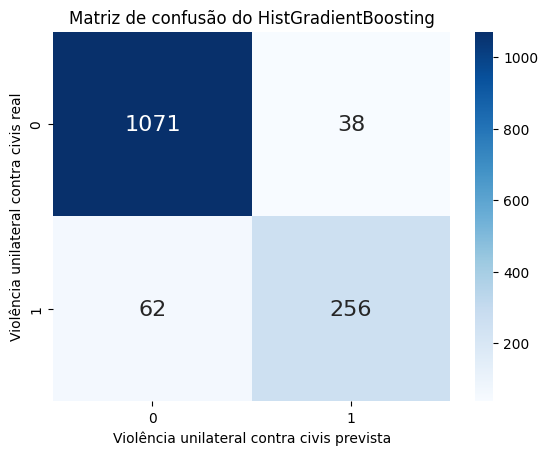

In [57]:
matriz_conf = confusion_matrix(
    y_verdadeiro,
    y_previsao
)

df_conf = pd.DataFrame(
    matriz_conf
)

sns.heatmap(
    df_conf,
    annot=True,
    annot_kws={"size": 16},
    fmt="d",
    cmap="Blues"
)

mpl.xlabel("Violência unilateral contra civis prevista")
mpl.ylabel("Violência unilateral contra civis real")
mpl.title("Matriz de confusão do HistGradientBoosting")

A matriz de confusão do modelo HistGradientBoosting reforça os resultados observados nas métricas de desempenho. Das 1109 observações pertencentes à classe negativa (ausência de violência unilateral contra civis), o modelo classificou corretamente 1071, cometendo apenas 38 falsos positivos. Isso indica uma elevada capacidade de identificar corretamente os casos em que não houve ocorrência de violência contra civis.

Em relação à classe positiva (presença de violência unilateral contra civis), das 318 ocorrências reais, o modelo identificou corretamente 256, deixando de detectar 62 casos. Esse resultado é consistente com o recall de aproximadamente 80,5%, indicando que o modelo consegue recuperar a maior parte dos eventos de interesse presentes no conjunto de teste.

Observa-se ainda que o número de falsos positivos (38) é inferior ao número de falsos negativos (62), demonstrando que o modelo adota uma postura relativamente conservadora ao atribuir a classe positiva. Essa característica contribui para a obtenção de uma precisão de 87,1%, indicando que a maioria das previsões positivas corresponde efetivamente a casos reais de violência unilateral contra civis.

De maneira geral, a matriz de confusão evidencia um equilíbrio favorável entre a capacidade de detecção de eventos positivos e a redução de alarmes falsos. O elevado número de verdadeiros positivos e verdadeiros negativos, aliado à baixa incidência de erros de classificação, explica os altos valores de precisão, recall, F1-score e ROC-AUC observados anteriormente.

## 9. Importância de cada variável

Além de avaliar o desempenho preditivo do modelo, também é importante compreender quais atributos exercem maior influência sobre suas decisões. Para isso, foi utilizada a técnica `Permutation Importance` [11], que estima a importância de cada variável a partir da degradação do desempenho do modelo quando os valores dessa variável são embaralhados aleatoriamente.

O procedimento consiste em medir inicialmente o desempenho do modelo utilizando a métrica escolhida, neste caso o F1-score. Em seguida, os valores de uma variável são permutados aleatoriamente, destruindo a relação existente entre essa variável e a variável alvo, enquanto todos os demais atributos permanecem inalterados. O desempenho é então recalculado e comparado ao desempenho original. Quanto maior for a redução observada no F1-score, maior será a importância daquela variável para as previsões do modelo.

Nesta etapa, é calculada a importância de cada atributo utilizando Permutation Importance. Para cada variável, seus valores são embaralhados 30 vezes (n_repeats=30) e a redução média observada no F1-score é utilizada como medida de importância. Quanto maior a queda de desempenho causada pelo embaralhamento de uma variável, maior a dependência do modelo em relação a essa informação. Os resultados são então organizados em ordem decrescente de importância para facilitar a interpretação do modelo.

O conjunto de teste é utilizado para o cálculo do `Permutation Importance` porque permite avaliar o impacto de cada variável sobre o desempenho do modelo em dados não utilizados durante o treinamento.

In [64]:
from sklearn.inspection import permutation_importance

r = permutation_importance(
    pipeline_final,
    X_teste,
    y_teste,
    scoring="f1",
    n_repeats=30,
    random_state=123
)

nomes_features = X_teste.columns

df_importancias = pd.DataFrame(
    {
        "atributo": nomes_features,
        "importancia": r.importances_mean,
        "desvio": r.importances_std,
    }
)

df_importancias = df_importancias.sort_values(
    "importancia",
    ascending=False
)

display(df_importancias.head(15))

,atributo,importancia,desvio
0,country,0.128591,0.008889
4,sb_dyad_count,0.108992,0.011408
6,ns_dyad_count,0.063981,0.005841
8,sb_intrastate_dyad_count,0.053321,0.008096
2,region,0.043629,0.008271
1,year,0.031919,0.007298
3,sb_exist,0.000000,0.000000
5,ns_exist,0.000000,0.000000
7,sb_intrastate_exist,0.000000,0.000000
9,sb_interstate_exist,0.000000,0.000000


Analisando o DataFrame resultante, nota-se que a variável mais importante foi `country`, com importância média de aproximadamente 0,129. Esse resultado sugere que a identidade específica do país contém informação altamente relevante para a previsão da ocorrência de violência unilateral contra civis. Em outras palavras, o modelo utiliza fortemente características associadas a cada país para realizar suas classificações.

Em seguida aparecem `sb_dyad_count` (0,109) e `ns_dyad_count` (0,064), que representam o número de díades envolvidas em conflitos estatais e não estatais, respectivamente. Esses resultados indicam que a intensidade e a complexidade dos conflitos presentes em determinado país e ano possuem papel importante na previsão da violência contra civis.

A variável `sb_intrastate_dyad_count` (0,053) também apresentou relevância significativa, sugerindo que a quantidade de conflitos intraestatais está bastante associada à ocorrência do target. Esse resultado é consistente com a análise exploratória realizada anteriormente, que indicou a predominância de conflitos intraestatais no conjunto de dados e sua possível relação com os eventos analisados.

Além disso, `region` (0,044) e `year` (0,032) apresentaram importância positiva moderada. A relevância de region sugere que fatores geográficos mais amplos também influenciam a previsão, enquanto a importância de year indica a existência de padrões temporais que contribuem para a ocorrência da variável alvo. Quanto a `year`, embora na análise exploratória a correlação temporal tenha parecido fraca, o teste com `Permutation Importance` revelou que essa correlação não é nula.

Por outro lado, chama atenção o fato de que as variáveis binárias `sb_exist`, `ns_exist`, `sb_intrastate_exist` e `sb_interstate_exist` apresentaram importância praticamente nula. Esse resultado sugere que, uma vez que o modelo já dispõe das variáveis de contagem (*_dyad_count) e das informações geográficas, a simples indicação da existência ou não de determinado tipo de conflito contribui muito pouco para melhorar as previsões. É provável que essas variáveis contenham informação redundante em relação às contagens correspondentes, fazendo com que o modelo não dependa delas para alcançar alto desempenho.

Por fim, `sb_interstate_dyad_count` apresentou uma importância ligeiramente negativa (-0,000081). Como o valor é extremamente próximo de zero e muito inferior ao seu próprio desvio-padrão, não há evidências de que essa variável exerça influência real sobre o modelo.

De forma geral, o `Permutation Importance` indica que o modelo depende principalmente de informações geográficas (country e region) e das variáveis que medem a intensidade dos conflitos (*_dyad_count), enquanto as variáveis binárias relacionadas apenas à existência dos conflitos apresentam contribuição praticamente nula. Esse resultado sugere que a quantidade e o contexto dos conflitos são mais informativos para a previsão da violência unilateral contra civis do que a simples ocorrência desses eventos.

A seguir estão os mesmos resultados em um gráfico de barras horizontal, que evidencia também o desvio padrão dos 30 embaralhamentos:

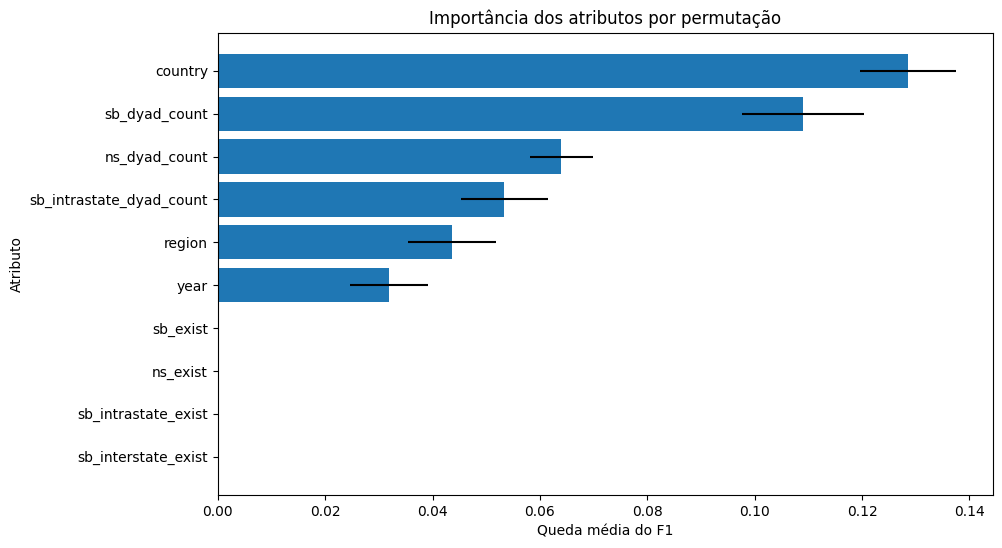

In [65]:
top = df_importancias.head(10)

mpl.figure(figsize=(10, 6))

mpl.barh(
    top["atributo"],
    top["importancia"],
    xerr=top["desvio"]
)

mpl.xlabel("Queda média do F1")
mpl.ylabel("Atributo")
mpl.title("Importância dos atributos por permutação")
mpl.gca().invert_yaxis()

mpl.show()

Ou seja, podemos observar que, de forma prática, apenas esses 6 primeiros atributos contribuem significativamente para o desempenho do modelo, como já foi discutido.

## 10. Estratégia oposta de interessante

Como estratégia extra, pensei em variar a semente aleatória a fim de testar a robustez do modelo. Se ele não variar significativamente, quer dizer que os resultados obtidos não foram fruto de um acaso (seja para o lado da sorte ou do azar). Definimos então (arbitrariamente e com um toque de aleatoriedade) algumas sementes aleatórias, e treinamos o modelo vencedor (o mesmo já usado em análises anteriores) com cada semente, guardando os resultados em uma lista. Ao final, conferimos com 10 casas decimais o desvio padrão, o mínimo e o máximo e a média do F1-score, a plotamos a partir disso um `boxplot`.

F1 médio = 0.8055004779
Desvio padrão = 0.0000000000
Mínimo = 0.8055004779
Máximo = 0.8055004779


Text(0.5, 1.0, 'Robustez do HGB para diferentes sementes')

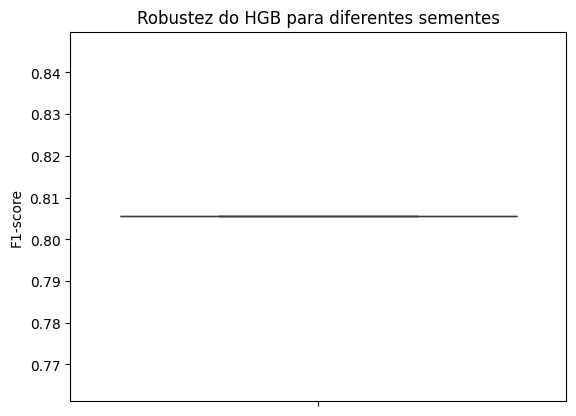

In [69]:
sementes = [0, 2, 42, 66, 123, 666, 1001, 71000, 66250, 188821]

scores = []

for semente in sementes:
    melhor_modelo = HistGradientBoostingClassifier(**melhor_trial_hgb.params,
                                                   random_state=semente
                                                  )
    
    pipeline_final = Pipeline(
        steps=[
        ("preprocessor", preprocessador),
        ("classifier", melhor_modelo)
        ]
    )

    score = cross_val_score(
        pipeline_final,
        X_treino,
        y_treino,
        scoring="f1",
        cv=cv,
        n_jobs=-1
    ).mean()

    scores.append(score)

import numpy as np

print(f"F1 médio = {np.mean(scores):.10f}")
print(f"Desvio padrão = {np.std(scores):.10f}")
print(f"Mínimo = {np.min(scores):.10f}")
print(f"Máximo = {np.max(scores):.10f}")

sns.boxplot(y=scores)
mpl.ylabel("F1-score")
mpl.title("Robustez do HGB para diferentes sementes")

O resultado foi surpreendente: a semente aleatória não alterou em nada o desempenho do modelo (dentro do escopo observado, claro)! Ou seja, ele é extremamente robusto, e não está nada sujeito ao acaso. O `boxplot` virou até unidimensional!

## 11. Conclusão e principais aprendizados

### 11.1 Recapitulação das conclusões obtidas ao longo do trabalho

O presente trabalho teve como objetivo prever a ocorrência de violência unilateral contra civis (os_exist) a partir de informações geográficas, temporais e relacionadas a conflitos armados presentes no conjunto de dados UCDP. Para isso, foram avaliados diferentes algoritmos de classificação, incluindo Regressão Logística, k-Nearest Neighbors (KNN), Árvore de Decisão, Floresta Aleatória e HistGradientBoosting, todos submetidos a um processo de otimização de hiperparâmetros utilizando o Optuna e validação cruzada estratificada.

Os resultados mostraram que todos os modelos apresentaram desempenho relativamente semelhante, com F1-score médio variando entre 78,51% e 80,55%, indicando que as variáveis disponíveis possuem elevado poder preditivo independentemente do algoritmo utilizado. Entre os modelos avaliados, o HistGradientBoosting apresentou o melhor desempenho durante a etapa de validação cruzada, sendo posteriormente selecionado para a avaliação final.

No conjunto de teste, o HistGradientBoosting alcançou 92,99% de acurácia, 87,07% de precisão, 80,50% de recall, 83,66% de F1-score e 96,58% de ROC-AUC. Quando comparado ao baseline, que apresentava F1-score igual a zero e ROC-AUC de 50%, observa-se um ganho substancial em todas as métricas avaliadas. Esses resultados demonstram que o modelo foi capaz de aprender padrões relevantes dos dados, superando com ampla margem uma estratégia baseada apenas na classe majoritária.

A análise de importância das variáveis por meio de Permutation Importance indicou que country foi o atributo mais relevante para as previsões do modelo, seguido por sb_dyad_count, ns_dyad_count, sb_intrastate_dyad_count, region e year. Esses resultados sugerem que tanto fatores geográficos quanto a intensidade dos conflitos desempenham papel fundamental na previsão da violência unilateral contra civis. Em contrapartida, variáveis binárias relacionadas apenas à existência dos conflitos apresentaram contribuição praticamente nula, indicando que as variáveis de contagem já capturam a maior parte da informação relevante.

Além disso, a análise de robustez baseada na variação da semente aleatória não causou alterações no desempenho do modelo, sugerindo que os resultados obtidos não são consequência de flutuações estocásticas do treinamento, mas sim de padrões efetivamente presentes nos dados.

### 11.2 O que aprendemos

O Tiamat foi um trabalho que permitiu aprofundar os conceitos da disciplina de forma prática, o que levou a aprendizados relevantes sobre a área:

1. É importante realizar uma boa análise exploratória sobre o conjunto de dados antes de mais nada, a fim de entender as especificidades dele e a partir disso abordá-lo da forma mais apropriada;
2. A ordem dos fatores importa: um erro "bobo" pode causar vazamento de dados, ter um bom planejamento é essencial para evitar esse tipo de engano;
3. É extremamente importante entender quais métricas de desempenho são apropriadas para avaliar o modelo. A acurácia pode enganar para datasets com target desbalanceado (foi o caso), então é importante checar mais de uma;
4. A validação cruzada e a otimização de hiperparâmetros servem para sugerir um melhor conjunto de hiperparâmetros que levem ao melhor modelo, mas a métrica de desempenho média da validação cruzada pode ter valor diferente de quando treinamos o modelo com todo o conjunto de treino e aplicamos no teste (se for muito diferente, no entanto, fica suspeito);
5. Nem todos os atributos necessariamente contribuem significativamente para o aprendizado do modelo;
6. O desempenho do modelo pode variar com o acaso... ou não: variando a semente aleatória não obtivemos diferença alguma (meu palpite inicial era diferente).

## 12. Descrição do uso de IA

Ao longo do trabalho, foi utilizada a IA genertiva Microsoft 365 Copilot, para alguns fins específicos:

1. Auxílio na escolha do conjunto de dados;
2. Indicação da documentação adequada para os modelos escolhidos;
3. Explicações didáticas sobre o código de documentações confusas;
4. Aconselhamento na definição do espaço de busca do optuna (hiperparâmetros escolhidos e limite deles);
5. Conferência da ordem lógica correta a fim de evitar vazamento de dados (montei um fluxograma da ordem a ser seguida, e requisitei ajustes, se necessário);
6. Referenciamento correto das fontes.

## Referências

1. UCDP. UCDP Country-Year Dataset on Organized Violence within Country Borders. Uppsala: Uppsala Conflict Data Program. Disponível em: https://ucdp.uu.se/downloads/. Acesso em: 16 nov. 2026.

2. UCDP. UCDP Organized Violence Country-Year Dataset Codebook. Disponível em: https://ucdp.uu.se/downloads/organizedviolencecy/UCDP_OrganizedViolenceCY_Codebook_261.pdf. Acesso em: 16 nov. 2026.

3. GEORGE, James; WITTEN, Daniela; HASTIE, Trevor; TIBSHIRANI, Robert. An Introduction to Statistical Learning. 2. ed. Cham: Springer, 2021.

4. RASCHKA, Sebastian. Model Evaluation, Model Selection, and Algorithm Selection in Machine Learning. 2020. Disponível em: http://arxiv.org/abs/1811.12808. Acesso em: 16 nov. 2026.

5. SCIKIT-LEARN. Model evaluation: quantifying the quality of predictions. Disponível em: https://scikit-learn.org/stable/modules/model_evaluation.html. Acesso em: 16 nov. 2026.

6. SCIKIT-LEARN. LogisticRegression. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html. Acesso em: 16 nov. 2026.

7. SCIKIT-LEARN. KNeighborsClassifier. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html. Acesso em: 16 nov. 2026.

8. SCIKIT-LEARN. DecisionTreeClassifier. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html. Acesso em: 16 nov. 2026.

9. SCIKIT-LEARN. RandomForestClassifier. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html. Acesso em: 16 nov. 2026.

10. SCIKIT-LEARN. HistGradientBoostingClassifier. Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html. Acesso em: 16 nov. 2026.

11. SCIKIT-LEARN. Permutation Feature Importance. Disponível em: https://scikit-learn.org/stable/modules/permutation_importance.html. Acesso em: 16 nov. 2026.

12. SEABORN. seaborn.heatmap. Disponível em: https://seaborn.pydata.org/archive/0.11/generated/seaborn.heatmap.html. Acesso em: 16 nov. 2026.

13. SPERAT, Walter. Using Optuna with Scikit-Learn the Right Way - Part 1. Disponível em: https://medium.com/@walter_sperat/using-optuna-with-sklearn-the-right-way-part-1-6b4ad0ab2451. Acesso em: 16 nov. 2026.

14. GEEKSFORGEEKS. HistGradientBoostingClassifier in Scikit-Learn. Disponível em: https://www.geeksforgeeks.org/machine-learning/histgradientboostingclassifier-in-sklearn/. Acesso em: 16 nov. 2026.

15. CASSAR, D. R. Notebooks de aula da disciplina ATP-203 (Aprendizado de Máquina): k-NN e métricas; divisão de dados em treino e teste; modelo linear e baseline; árvore de decisão e floresta aleatória; classificação binária; validação cruzada e otimização de hiperparâmetros; vazamento de dados; dados sintéticos e pipeline; otimização de hiperparâmetros com optuna. Ilum Escola de Ciência, 2026.